# Wetland Sentinel | Water extent with NDWI

**Optical remote sensing • Reproducible teaching demo • CPU only • No downloads**

How much of a wetland is mapped as open water, and how does cloud masking affect the comparison across dates? This notebook uses **synthetic Sentinel-2-like reflectance** for a separate calibration scene and six monitoring dates. The data are generated here: they represent no real wetland, observation, or location.

**Workflow:** build scenes → mask invalid pixels → compute NDWI → calibrate on a separate scene → evaluate on the monitoring dates → compare water area on a common clear footprint.

**Outputs:** reflectance and NDWI maps, F1/IoU against synthetic reference labels, a water-area time series, and `outputs/ndwi_monitoring_summary.csv`.

## 1 · Method and configuration

McFeeters' Normalized Difference Water Index is $$\operatorname{NDWI} = \frac{\rho_{\mathrm{green}}-\rho_{\mathrm{NIR}}}{\rho_{\mathrm{green}}+\rho_{\mathrm{NIR}}}.$$

We use the equivalents of Sentinel-2 **B03 (green)** and **B08 (near infrared)**, both at nominal **10 m** resolution. Cloudy pixels and nonpositive denominators are excluded. The rule is `NDWI >= threshold` on valid pixels; zero is a baseline, not a universal water boundary. All pixel areas in this synthetic grid are modeled as 100 m².

In [1]:
from datetime import date
from pathlib import Path
import csv

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.dates import DateFormatter
from matplotlib.patches import Patch
import numpy as np

SEED = 1977
GRID = (160, 220)
PIXEL_METRES = 10
PIXEL_HECTARES = PIXEL_METRES**2 / 10_000
CANDIDATE_THRESHOLDS = np.linspace(-0.20, 0.40, 121)
MONITORING = [
    (date(2025, 4, 15), 0.94), (date(2025, 5, 15), 1.03),
    (date(2025, 6, 15), 0.98), (date(2025, 7, 15), 0.85),
    (date(2025, 8, 15), 0.75), (date(2025, 9, 15), 0.82),
]
OUTPUT_DIR = Path("outputs")

plt.rcParams.update({
    "figure.dpi": 125, "font.size": 10, "axes.titleweight": "semibold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#243747", "text.color": "#172D3D",
})
print(f"Grid: {GRID[1]} × {GRID[0]} pixels | Pixel area: {PIXEL_HECTARES:.2f} ha")

Grid: 220 × 160 pixels | Pixel area: 0.01 ha


## 2 · Build the observation and reference layers

The synthetic reference is set by basin geometry, independently of the NDWI classification. Mixed shoreline pixels, variable water and land spectra, wet mud, band noise and moving cloud masks make the classification deliberately imperfect. The calibration basin differs from the monitoring basin in location and geometry. The monitoring basin stays in the same position across dates.

In [2]:
def simulate_scene(stage, seed, *, calibration=False):
    rng = np.random.default_rng(seed)
    y, x = np.meshgrid(
        np.linspace(-1, 1, GRID[0]), np.linspace(-1, 1, GRID[1]), indexing="ij"
    )
    cx, cy, sx, sy = (-0.18, 0.11, 0.65, 0.53) if calibration else (-0.07, -0.04, 0.72, 0.49)
    phase = 0.80 if calibration else 0.10
    radius = np.hypot((x - cx) / sx, (y - cy) / sy)
    shore = stage - radius + 0.065 * np.sin(13 * x + phase) * np.cos(9 * y - phase)
    reference = shore >= 0
    water_fraction = np.clip(0.50 + shore / 0.15, 0, 1)

    turbidity = 0.50 + 0.50 * np.sin(5 * x - 3 * y + rng.uniform(-0.4, 0.4))
    vegetation = 0.50 + 0.50 * np.cos(8 * x + 4 * y)
    wet_mud = (shore > -0.17) & (shore < -0.02) & (np.sin(9 * x - 11 * y + phase) > 0.15)
    green_water, nir_water = 0.055 + 0.042 * turbidity, 0.025 + 0.052 * turbidity
    green_land = np.where(wet_mud, 0.116, 0.080 + 0.043 * vegetation)
    nir_land = np.where(wet_mud, 0.112, 0.158 + 0.150 * vegetation)
    green = np.clip(water_fraction * green_water + (1 - water_fraction) * green_land
                    + rng.normal(0, 0.009, GRID), 0, 1)
    nir = np.clip(water_fraction * nir_water + (1 - water_fraction) * nir_land
                  + rng.normal(0, 0.011, GRID), 0, 1)
    cloud_x, cloud_y = rng.uniform(-0.72, 0.72), rng.uniform(-0.48, 0.48)
    clouds = (((x - cloud_x) / 0.34)**2 + ((y - cloud_y) / 0.24)**2
              + 0.14 * np.sin(27 * x) * np.cos(22 * y) < 1)
    green[clouds], nir[clouds] = 0.67, 0.61
    return {"green": green, "nir": nir, "clouds": clouds, "reference": reference}


def water_index(green, nir, clouds):
    denominator = green + nir
    valid = (~clouds & np.isfinite(green) & np.isfinite(nir)
             & (denominator > 1e-8))
    return np.divide(green - nir, denominator, out=np.full(green.shape, np.nan), where=valid)


def add_index(scene):
    ndwi = water_index(scene["green"], scene["nir"], scene["clouds"])
    return {**scene, "ndwi": ndwi, "valid": np.isfinite(ndwi)}


calibration = add_index(simulate_scene(0.93, SEED, calibration=True))
monitoring = [
    (day, add_index(simulate_scene(stage, SEED + i + 1)))
    for i, (day, stage) in enumerate(MONITORING)
]
assert all(np.isnan(s["ndwi"][s["clouds"]]).all() for s in [calibration, *[s for _, s in monitoring]])
assert np.isnan(water_index(np.zeros((1, 1)), np.zeros((1, 1)), np.zeros((1, 1), dtype=bool))).all()

## 3 · Calibrate without using monitoring labels

For each candidate threshold, we compute positive-class **F1** and **IoU** on clear pixels. We select the maximum calibration F1 (ties go to the threshold closest to zero, then the lower value) and freeze it before scoring any monitoring scene. F1 balances precision and recall, while IoU is the fraction of the union of mapped and reference water that the two maps share.

Frozen threshold = -0.190 | Calibration F1 = 0.900


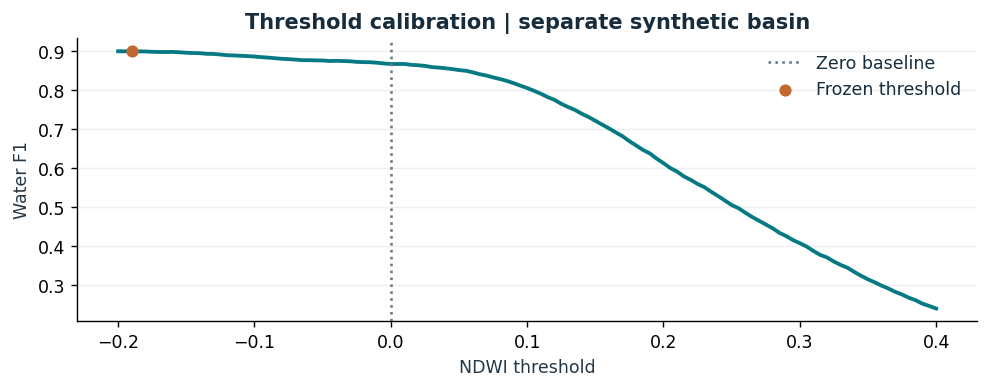

In [3]:
def ratio(numerator, denominator):
    return numerator / denominator if denominator else float("nan")


def evaluate(prediction, reference, valid):
    pred, truth = prediction[valid], reference[valid]
    tp = int(np.count_nonzero(pred & truth))
    fp = int(np.count_nonzero(pred & ~truth))
    fn = int(np.count_nonzero(~pred & truth))
    tn = int(np.count_nonzero(~pred & ~truth))
    return {"tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "precision": ratio(tp, tp + fp), "recall": ratio(tp, tp + fn),
            "f1": ratio(2 * tp, 2 * tp + fp + fn), "iou": ratio(tp, tp + fp + fn)}


cal_f1 = np.array([
    evaluate(calibration["ndwi"] >= threshold, calibration["reference"], calibration["valid"])["f1"]
    for threshold in CANDIDATE_THRESHOLDS
])
indices = np.flatnonzero(np.isclose(cal_f1, np.nanmax(cal_f1), rtol=0, atol=1e-12))
best_i = min(indices, key=lambda i: (round(abs(CANDIDATE_THRESHOLDS[i]), 12), CANDIDATE_THRESHOLDS[i]))
threshold = float(CANDIDATE_THRESHOLDS[best_i])
print(f"Frozen threshold = {threshold:+.3f} | Calibration F1 = {cal_f1[best_i]:.3f}")

fig, ax = plt.subplots(figsize=(7.8, 3.0), layout="constrained")
ax.plot(CANDIDATE_THRESHOLDS, cal_f1, color="#067A83", linewidth=2.2)
ax.axvline(0, color="#687A88", linestyle=":", label="Zero baseline")
ax.scatter(threshold, cal_f1[best_i], color="#C46831", zorder=3, label="Frozen threshold")
ax.set(title="Threshold calibration | separate synthetic basin", xlabel="NDWI threshold", ylabel="Water F1")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
plt.show()

## 4 · Inspect a monitoring date

**Blue** is mapped or reference water, **sand** is land, and **gray** is excluded. The map comparison masks the same pixels in prediction and reference. This avoids scoring unseen areas as dry land. The first monitoring date is displayed by design, not selected based on its score.

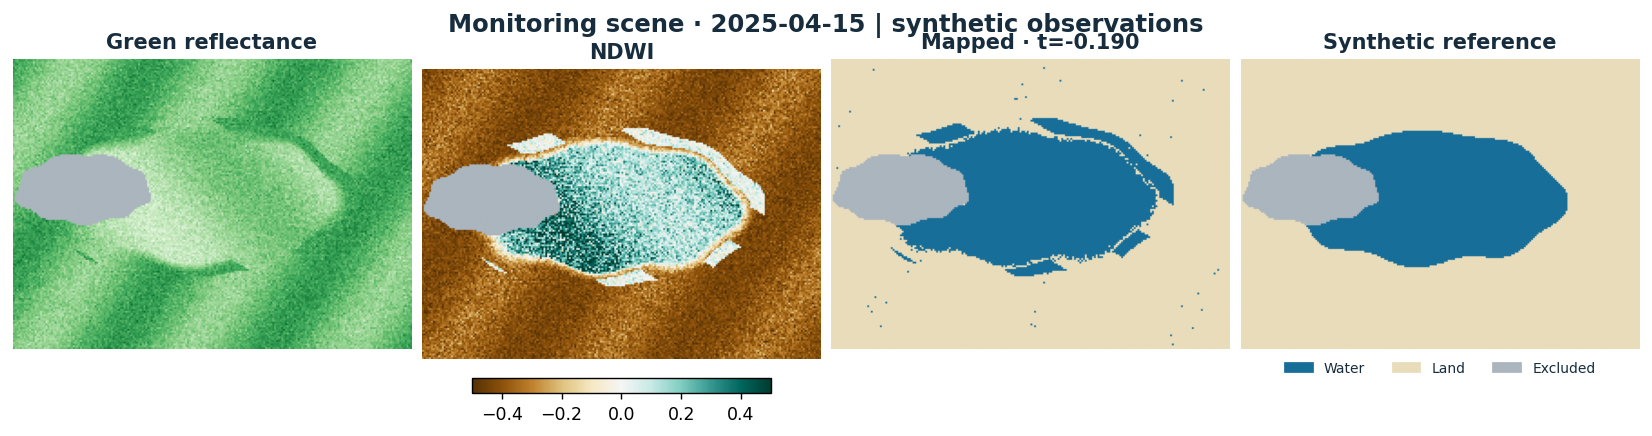

In [4]:
day, example = monitoring[0]
valid = example["valid"]
classification = (example["ndwi"] >= threshold).astype(int)
land, water, excluded = "#E9DCBA", "#176E99", "#AAB5BE"
class_cmap = ListedColormap([land, water]).with_extremes(bad=excluded)
ndwi_cmap = plt.colormaps["BrBG"].with_extremes(bad=excluded)
fig, axes = plt.subplots(1, 4, figsize=(13.1, 3.35), layout="constrained")
axes[0].imshow(np.ma.masked_where(~valid, example["green"]),
               cmap=plt.colormaps["Greens"].with_extremes(bad=excluded), vmin=0.02, vmax=0.17)
image = axes[1].imshow(example["ndwi"], cmap=ndwi_cmap, vmin=-0.5, vmax=0.5)
axes[2].imshow(np.ma.masked_where(~valid, classification), cmap=class_cmap, vmin=0, vmax=1)
axes[3].imshow(np.ma.masked_where(~valid, example["reference"]), cmap=class_cmap, vmin=0, vmax=1)
for ax, title in zip(axes, ["Green reflectance", "NDWI", f"Mapped · t={threshold:+.3f}", "Synthetic reference"]):
    ax.set_title(title)
    ax.set_axis_off()
fig.colorbar(image, ax=axes[1], orientation="horizontal", shrink=0.75, pad=0.03)
axes[3].legend(handles=[Patch(color=c, label=s) for c, s in [(water, "Water"), (land, "Land"), (excluded, "Excluded")]],
               loc="upper center", bbox_to_anchor=(0.5, 0), frameon=False, ncol=3, fontsize=8)
fig.suptitle(f"Monitoring scene · {day.isoformat()} | synthetic observations", fontsize=14, fontweight="bold")
plt.show()

## 5 · Compare area on pixels visible on every date

Each date has its own clear-area classification scores. For the area time series, we use the **intersection** of valid footprints across all six dates and report its spatial coverage. This holds the denominator and location fixed but discards some otherwise useful observations. Neither the mapped area on a single date nor the common-footprint area should be interpreted as the total wetland area.

Common valid footprint: 72.4% of the grid
Mean per-date F1: zero baseline 0.866 | calibrated 0.895
CSV report: outputs/ndwi_monitoring_summary.csv


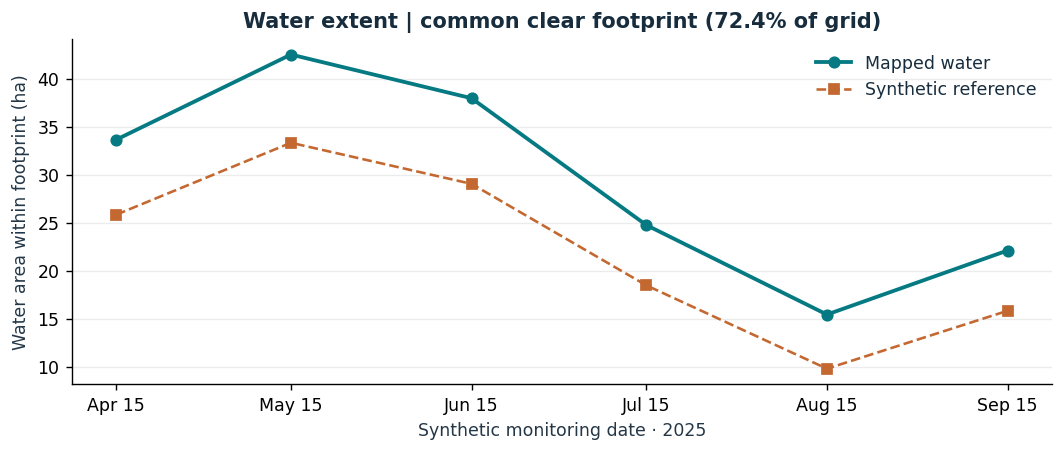

In [5]:
common = np.logical_and.reduce([scene["valid"] for _, scene in monitoring])
assert common.any()
common_fraction = float(common.mean())
rows = []
for day, scene in monitoring:
    valid = scene["valid"]
    mapped = scene["ndwi"] >= threshold
    scores = evaluate(mapped, scene["reference"], valid)
    baseline = evaluate(scene["ndwi"] >= 0, scene["reference"], valid)
    assert sum(scores[k] for k in ("tp", "fp", "fn", "tn")) == valid.sum()
    rows.append({
        "date": day.isoformat(),
        "threshold": round(threshold, 3),
        "clear_coverage_pct": round(100 * valid.mean(), 2),
        "common_coverage_pct": round(100 * common_fraction, 2),
        "baseline_zero_f1": round(baseline["f1"], 4),
        "calibrated_f1": round(scores["f1"], 4),
        "calibrated_iou": round(scores["iou"], 4),
        "mapped_water_clear_ha": round(np.count_nonzero(mapped & valid) * PIXEL_HECTARES, 2),
        "mapped_water_common_ha": round(np.count_nonzero(mapped & common) * PIXEL_HECTARES, 2),
        "reference_water_common_ha": round(np.count_nonzero(scene["reference"] & common) * PIXEL_HECTARES, 2),
        **{k: scores[k] for k in ("tp", "fp", "fn", "tn")},
    })

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
report = OUTPUT_DIR / "ndwi_monitoring_summary.csv"
with report.open("w", encoding="utf-8", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

print(f"Common valid footprint: {100 * common_fraction:.1f}% of the grid")
print(f"Mean per-date F1: zero baseline {np.mean([r['baseline_zero_f1'] for r in rows]):.3f} | "
      f"calibrated {np.mean([r['calibrated_f1'] for r in rows]):.3f}")
print(f"CSV report: {report}")

dates = [date.fromisoformat(row["date"]) for row in rows]
fig, ax = plt.subplots(figsize=(8.4, 3.5), layout="constrained")
ax.plot(dates, [r["mapped_water_common_ha"] for r in rows],
        color="#067A83", marker="o", linewidth=2.2, label="Mapped water")
ax.plot(dates, [r["reference_water_common_ha"] for r in rows],
        color="#C46831", marker="s", linestyle="--", label="Synthetic reference")
ax.set(title=f"Water extent | common clear footprint ({common_fraction:.1%} of grid)",
       ylabel="Water area within footprint (ha)", xlabel="Synthetic monitoring date · 2025")
ax.xaxis.set_major_formatter(DateFormatter("%b %d"))
ax.set_xticks(dates)
ax.grid(axis="y", alpha=0.23)
ax.legend(frameon=False)
plt.show()

## Interpretation and limitations

- NDWI responds to both water and surface reflectance. Wet soil, emergent vegetation, shallow water, turbidity and shadows can make water mapping ambiguous. Here clouds are known exactly and no shadow detection is simulated.
- Inspect the zero-threshold baseline and the calibrated result together. A gain or loss here measures behavior of this simulator, not transferability to real scenes. The six dates share a basin and are not independent estimates of generalization across wetlands.
- For real monitoring, use co-registered surface reflectance with sensor-specific quality masks, verify the spatial footprint, select thresholds without test leakage, and validate against independent reference data. Use appropriate pixel areas for the raster projection.

**References:** [McFeeters (1996), original NDWI paper](https://doi.org/10.1080/01431169608948714) · [Copernicus Sentinel-2 mission and spectral bands](https://sentiwiki.copernicus.eu/web/s2-mission).